## Panel dyskusyjny agentów

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/pl/10_1_Application_discussion_panel_with_supervisor.ipynb)

| | |
|---|---|
| 🎯 **Czego się nauczysz** | Panel dyskusyjny czterech agentów: moderator przekazuje pracę agentom researcherowi, ekspertowi i krytykowi. |
| 🔑 **Klucze API** | `OPENAI_API_KEY`, `TAVILY_API_KEY` |
| 💲 **Koszt API** | umiarkowany – pętla wieloagentowa z wieloma dłuższymi zapytaniami |
| ⏱️ **Czas wykonania** | ~2 min |

### Instalacja bibliotek

In [ ]:
# Zainstaluj bezpośrednie zależności używane w tym notebooku.
# Pomijane, gdy brak pip, np. w środowisku `uv sync`, które ma je już zainstalowane (zob. README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langgraph-supervisor langchain-tavily langchain-openai python-dotenv
# Google Colab: dodaj OPENAI_API_KEY w panelu Secrets (🔑) i zezwól notatnikowi na dostęp.
# Odkomentuj te linie, aby wczytać klucz z Colab Secrets do bieżącej sesji:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Lokalnie umieść OPENAI_API_KEY=... w pliku .env; nie commituj klucza.
# Dla wyszukiwania Tavily dodaj też TAVILY_API_KEY w Colab Secrets lub lokalnym pliku .env.
# from google.colab import userdata
# os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")

In [2]:
from langchain_core.messages import convert_to_messages
from typing import Annotated
from langchain_core.tools import tool, InjectedToolCallId
from langgraph.prebuilt import InjectedState, create_react_agent
from langgraph.graph import StateGraph, START, MessagesState, END
from langgraph.types import Command

from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search_results = web_search.invoke("Kto jest prezydentem Polski?")

print(web_search_results["results"][0]["content"])

| Ilustracja Gabriel Narutowicz – pierwszy prezydent Polski |
| Obecny prezydent |
| Obecny Prezydent Polski_(cropped).jpg "Karol Nawrocki") Karol Nawrocki |
| Stanowisko |
| Państwo | Polska |
| Data utworzenia | 11 grudnia 1922 |
| Pierwszy prezydent | Gabriel Narutowicz |
| Obecny prezydent | Karol Nawrocki |
| Obecny od | 6 sierpnia 2025 |
| Siedziba | Pałac Prezydencki w Warszawie |
| Strona internetowa |



[edytuj") | edytuj kod")] [...] Andrzej Duda

Osobą pełniącą najkrócej tymczasowo obowiązki prezydenta Polski był Bogdan Borusewicz (1 dzień). Najkrócej urzędującym prezydentem Polski był Gabriel Narutowicz, sprawujący urząd przez 3 dni. Wśród prezydentów na uchodźstwie najkrócej urzędującym prezydentem był Ryszard Kaczorowski (521 dni), wśród głów państwa Polski Ludowej Józef Cyrankiewicz (461 dni), a w III RP Wojciech Jaruzelski (356 dni).

 Gabriel Narutowicz

  Gabriel Narutowicz
 Józef Cyrankiewicz [...] Henryk Jabłoński
 Edward Raczyński.jpg "Edward Raczyński")

  Edward

### Funkcje pomocnicze

In [4]:
def pretty_print_messages(chunk):
    """Wyświetla najnowszą wiadomość z każdego kroku agenta (stream z subgraphs=True)."""
    namespace, update = chunk
    if not namespace:  # pomiń aktualizacje grafu nadrzędnego, pokaż pracę wewnątrz agentów
        return
    print(f"Aktualizacja z podgrafu {namespace[-1].split(':')[0]}:\n")
    for node_name, node_update in update.items():
        if node_update and "messages" in node_update:
            print(f"Węzeł: {node_name}")
            convert_to_messages(node_update["messages"])[-1].pretty_print()
    print("\n")

### Agent researcher

In [5]:
research_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[web_search],
    prompt=(
     "Jesteś Researcherem. Masz dostęp do wyników wyszukiwarki (RESEARCH).\n"
     "Twoim celem jest dostarczyć rzeczowe, krótkie fakty i dane wspierające temat.\n"
     "Odnoś się do fragmentów i nie fantazjuj. Pisz po polsku, zwięźle."
        "- Po tym jak skończysz swoje zadanie odpowiedz bezpośrednio do moderatora\n"
        "- Odpowiadaj używając tylko rezultatów swojej pracy, nie załączaj tekstu."
    ),
    name="research_agent",
)

/tmp/ipykernel_647187/140887706.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


### Agent ekspert

In [6]:
expert_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[],
    prompt=(
       "Jesteś Ekspertem. Z dostępnych faktów zaproponuj praktyczne rozwiązanie/plan.\n"
       "Uwzględnij kroki, wymagania i minimalny zestaw decyzji. Pisz po polsku, konkretnie."
        "- Po tym jak skończysz swoje zadanie odpowiedz bezpośrednio do moderatora\n"
        "- Odpowiadaj używając tylko rezultatów swojej pracy, nie załączaj tekstu."
    ),
    name="expert_agent",
)

/tmp/ipykernel_647187/4129629606.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  expert_agent = create_react_agent(


### Agent krytyk

In [7]:
critic_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[],
    prompt=(
     "Jesteś Krytykiem. Twoją rolą jest znaleźć luki, ryzyka i niejasności w propozycji.\n"
     "Zadawaj dociekliwe pytania i wskaż brakujące elementy. Bądź konstruktywny."
        "- Po tym jak skończysz swoje zadanie odpowiedz bezpośrednio do moderatora\n"
        "- Odpowiadaj używając tylko rezultatów swojej pracy, nie załączaj tekstu."
    ),
    name="critic_agent",
)

/tmp/ipykernel_647187/3061508179.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  critic_agent = create_react_agent(


In [8]:
def create_handoff_tool(*, agent_name: str, description: str | None = None):
    name = f"transfer_to_{agent_name}"
    description = description or f"Ask {agent_name} for help."

    @tool(name, description=description)
    def handoff_tool(
        state: Annotated[MessagesState, InjectedState],
        tool_call_id: Annotated[str, InjectedToolCallId],
    ) -> Command:
        tool_message = {
            "role": "tool",
            "content": f"Successfully transferred to {agent_name}",
            "name": name,
            "tool_call_id": tool_call_id,
        }
        return Command(
            goto=agent_name,
            update={**state, "messages": state["messages"] + [tool_message]},
            graph=Command.PARENT,
        )

    return handoff_tool

# Handoffs
assign_to_research_agent = create_handoff_tool(
    agent_name="research_agent",
    description="Assign task to a researcher agent.",
)

assign_to_expert_agent = create_handoff_tool(
    agent_name="expert_agent",
    description="Assign task to a expert agent.",
)

assign_to_critic_agent = create_handoff_tool(
    agent_name="critic_agent",
    description="Assign task to a critic agent.",
)

### Agent moderator

In [9]:
supervisor_agent = create_react_agent(
    model="openai:gpt-6.1-sol",
    tools=[assign_to_research_agent, assign_to_expert_agent, assign_to_critic_agent],
    prompt=(
        "Jesteś Moderatorem dyskusji w której biorą udział 3 agenci: Researcher, Krytyk i Ekspert . Decydujesz, czy kończymy, czy kontynuujemy.\n"
        "Jeśli kontynuujemy, podaj KRÓTKIE kolejne zapytanie badawcze (research_query) "
        "dla Researchera, Krytyka lub Eksperta. Pisz po polsku. Jeżeli kończymy podsumuj dyskusję i przedstaw w utrukturyzowany i czytelny sposób odpowiedź na pytanie."
        "- Researcher. Wyszukuje informacje i podaje fakty, które stanowią podstawe dalszej dyskucji\n"
        "- Krytyk. Patrzy asertywnie na dotychczasowe wnioski i wskazuje słabe punkty i elemanty do zmiany lub poprawienia\n"
        "- Ekspert. Wyciąga wnioski i stawia tezy. Stara się rozwiązać zadanie na podstawie informacji otrzyumanych od Researchera i Krytyka\n"
        "Przypisz pracę jednemu agentowi naraz, nie wywołuj agentów równolegle.\n"
        "Samodzielnie nie bierz udziału w dyskusji pracy."
    ),
    name="supervisor",
)

/tmp/ipykernel_647187/3075312597.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  supervisor_agent = create_react_agent(


### Budowa grafu

In [10]:
supervisor = (
    StateGraph(MessagesState)
    .add_node(supervisor_agent, destinations=("research_agent", "expert_agent", "critic_agent", END))
    .add_node(research_agent)
    .add_node(expert_agent)
    .add_node(critic_agent)
    .add_edge(START, "supervisor")
    .add_edge("research_agent", "supervisor")
    .add_edge("expert_agent", "supervisor")
    .add_edge("critic_agent", "supervisor")
    .compile()
)

### Wyświetl graf

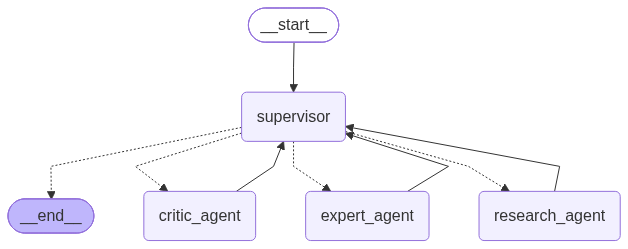

In [11]:
from IPython.display import display, Image

display(Image(supervisor.get_graph().draw_mermaid_png()))

### Przeprowadź dyskusję na zadany temat i wyświetl odpowiedź

In [12]:
for chunk in supervisor.stream(
    {
        "messages": [
            {
                "role": "user",
                "content":" Jakiej dziedziny najlepiej uczyć się, żeby mieć dobrze płatny i interesujący zawód za 10 lat.",
            }
        ]
    },

    subgraphs=True,
):
    pretty_print_messages(chunk)

Aktualizacja z podgrafu supervisor:

Węzeł: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**Researcher — research_query:** Jakie dziedziny mają najlepsze perspektywy dobrze płatnej i interesującej pracy około 2036 roku? Uwzględnij Polskę i rynek międzynarodowy, wpływ AI, bariery wejścia oraz niepewność prognoz.\n', 'annotations': [], 'id': 'msg_035aa0cccbc54281006ad7148721dc87d2b23b536ccda416ed', 'phase': 'commentary'}, {'arguments': '{}', 'call_id': 'call_nAv0OQjOdO7VY4r6nbJqSGcO', 'name': 'transfer_to_research_agent', 'type': 'function_call', 'id': 'fc_035aa0cccbc54281006ad71488eae887d284c8004df29fc221', 'status': 'completed'}]
Tool Calls:
  transfer_to_research_agent (call_nAv0OQjOdO7VY4r6nbJqSGcO)
 Call ID: call_nAv0OQjOdO7VY4r6nbJqSGcO
  Args:




Aktualizacja z podgrafu research_agent:

Węzeł: agent
================================== Ai Message ==================================
Name: research_agent

[{'arguments': '{"query":"Future of Jobs Report 2025 fastest growing jobs 2030 AI big data cybersecurity renewable energy 39% skills","include_domains":["weforum.org"],"exclude_domains":[],"search_depth":"advanced","include_images":false,"time_range":null,"topic":"general","start_date":null,"end_date":null}', 'call_id': 'call_yQqsAnVaxYZ3CZkJPOoKYFT7', 'name': 'tavily_search', 'type': 'function_call', 'id': 'fc_035aa0cccbc54281006ad7148ef21887d28b77352c99b5cddf', 'status': 'completed'}, {'arguments': '{"query":"Poland 2025 salary guide cybersecurity AI engineer salary Hays 2025 PLN","include_domains":["hays.pl"],"exclude_domains":[],"search_depth":"advanced","include_images":false,"time_range":null,"topic":"general","start_date":null,"end_date":null}', 'call_id': 'call_0o15DrrdkVWrqklXZeyDmWtX', 'name': 'tavily_search', 'type': 'fu

Aktualizacja z podgrafu research_agent:

Węzeł: tools
================================= Tool Message =================================
Name: tavily_search

{"query": "Future of Jobs Report 2025 fastest growing jobs 2030 AI big data cybersecurity renewable energy 39% skills", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://reports.weforum.org/docs/WEF_Future_of_Jobs_Report_2025.pdf", "title": "WEF_Future_of_Jobs_Report_2025.pdf", "content": "These expectations are reflected in the list of predicted fastest-growing job roles in the country, which includes Robotics Engineers, Renewable Energy Engineers, and Autonomous and Electric Vehicle Specialists. Employers anticipate 44% of on-the-job skills to be disrupted by 2030, higher than the global average of 39%. AI and big data, technological literacy, and networks and cybersecurity are identified as the fastest-growing skills in the country, in addition to a higher-than-average expected growth in the 

Aktualizacja z podgrafu research_agent:

Węzeł: tools
================================= Tool Message =================================
Name: tavily_search

{"query": "Poland 2025 salary guide cybersecurity AI engineer salary Hays 2025 PLN", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.hays.pl/en/salary-guide/recruiting-trends", "title": "Hays Poland Salary Guide 2026 | Recruiting Trends", "content": "### However, employees are not limiting their expectations. More people expect pay rises in the next 12 months than a year ago.\n\nIncrease by more than 20%\n\nIncrease by 10%-20%\n\nIncrease by less than 10%\n\nStay the same\n\nDecrease\n\n80 60 40 20 0\n\n2025 2026\n\n4%\n\n11%\n\n37%\n\n46%\n\n2%\n\n2%\n\n10%\n\n54%\n\n32%\n\n2%\n\n\\Employees were asked how their remuneration will change in the coming year\n\n### This may be attributed to a declining level of satisfaction among professionals regarding their compensation\n\n3% want to upski

Aktualizacja z podgrafu research_agent:

Węzeł: tools
================================= Tool Message =================================
Name: tavily_search

{"query": "Poland 2035 skills forecast health professionals ICT engineering Cedefop 2025", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.cedefop.europa.eu/files/skills_forecast_-_poland_2025.pdf", "title": "[PDF] 2025 skills forecast Poland - Cedefop", "content": "trend are, for example, legal, social, cultural and related associate professionals or chief executives, senior officials and legislators. The total number of medium-skilled workers is forecast to decrease slightly until 2035, as a general shift towards upskilling is forecast. Still, in 2035 the highest number of persons employed is expected to be among the medium-skilled. Among those medium-skilled workers, the number of health professionals, Information and communications technology professionals, building and related trades 

...

Aktualizacja z podgrafu supervisor:

Węzeł: agent
================================== Ai Message ==================================
Name: supervisor

[{'id': 'rs_035aa0cccbc54281006ad714b30da087d2ad853be6b6fb8454', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq1xS123c3tJ3ac_Ie7mhI2crcOLMCcJRGrTRNJHxS-c03M17Sg_3q35iiXBxkwwkBbVBhuAF0YO799Laf98-kCiABftvZL5gdMt13AmU4V4mhrrzw-WZlUsrnXoVsLjW6FpEXTX3za-vQRoNX8Pyab3M5HmQpPThTNVXzx93KnYfaeoDggU62ieJgypA0ehtyuC8rPdMxKrAC5zCrt-H7qbch3QdhnAQyFpDzdzqMqrNTsx0jZEwm1zMxdjZSM0yt2yr53aJSBYXf29yvUde3PAZjAxZovqUD3DUkkFbGz6eL0L6G186It0FUbMQO5AjU_rK1MvB-o11vDG5Nic52qjghP8VxiZa3TRd7yM9REpUfMFc9CVjgmKLUHEkeNP5X2nMhoRizLU5HUiE_BqI84wk76c-w4uPS3cjoPA9YC7J_8TA7U3D_dccu85IqwQ00RNDS9398kmrHSMRmGd1RPg75cujnYWZ8TRJDv7mnpqDGIYPXH3alWz8NfN2Vs_7mFiRZSSIEt6EJ2cmfbJKKc8c19RFivTvGgflB482FbgMmlgcePKk509Ea37bi0FV7SqbWG6GScpHjw4aODL6z2fcGBpnmjz44RADjM95mbEEDFwO2GcXYB-4RBC2PVnBFtxSWVKP8wJqbGYnhgBE4nFUWrIxkRbUKzIXqf9I5mRsVtH-XWMDMjqqsI5gNqpqW6

Aktualizacja z podgrafu critic_agent:

Węzeł: agent
================================== Ai Message ==================================
Name: critic_agent

Moderatorze — rekomendowane dziedziny są rozsądną krótką listą, ale materiał nie uzasadnia wskazania jednej „najlepszej”.

### Luki i ryzyka
- **Wzrost popytu nie oznacza wysokich zarobków.** Liczą się także liczba kandydatów, specjalizacja, produktywność i budżety pracodawców. Brakuje porównywalnych danych płacowych dla Polski.
- **Mediany z USA nie opisują polskiego rynku ani płac początkujących.** Nie należy przeliczać ich na złotówki jako potencjalnych zarobków użytkownika.
- **Popyt na ekspertów nie oznacza łatwego wejścia.** W cyberbezpieczeństwie często potrzebne jest wcześniejsze doświadczenie w IT; AI i analiza danych wymagają solidnej matematyki, programowania oraz praktyki. Trzeba ocenić dostępność staży i pierwszej pracy.
- **Medycyna, automatyka i AI to różne koszty kariery.** Należy uwzględnić długość nauki, uprawnienia, 

Aktualizacja z podgrafu supervisor:

Węzeł: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**Ekspert — research_query:** Na podstawie faktów i zastrzeżeń zaproponuj warunkową rekomendację: jeden wybór dla osoby lubiącej technikę, alternatywy według zainteresowań i prosty sposób sprawdzenia dopasowania. Bez obietnic zarobków.\n', 'annotations': [], 'id': 'msg_035aa0cccbc54281006ad714ca4b9087d2bef72b2744cca8e7', 'phase': 'commentary'}, {'arguments': '{}', 'call_id': 'call_b6ePqOWHuXRX8gx2pDhkGNjG', 'name': 'transfer_to_expert_agent', 'type': 'function_call', 'id': 'fc_035aa0cccbc54281006ad714cbda7487d283ff78dd9317f832', 'status': 'completed'}]
Tool Calls:
  transfer_to_expert_agent (call_b6ePqOWHuXRX8gx2pDhkGNjG)
 Call ID: call_b6ePqOWHuXRX8gx2pDhkGNjG
  Args:




Aktualizacja z podgrafu expert_agent:

Węzeł: agent
================================== Ai Message ==================================
Name: expert_agent

Moderatorze — **dla osoby lubiącej technikę rekomenduję informatykę z mocnymi podstawami matematycznymi, a następnie specjalizację w cyberbezpieczeństwie lub zastosowaniach AI w konkretnej branży.** To elastyczna ścieżka, nie gwarancja wysokich zarobków w 2036 roku.

### Wybór według zainteresowań

| Co najbardziej Cię interesuje? | Kierunek nauki | Najważniejsze wymagania i ograniczenia |
|---|---|---|
| Kod, logika, rozwiązywanie abstrakcyjnych problemów | **Informatyka → cyberbezpieczeństwo lub AI i dane** | Matematyka, programowanie, angielski i projekty. Wejście do pierwszej pracy może być trudne; cyberbezpieczeństwo często wymaga wcześniejszego doświadczenia IT. |
| Urządzenia, fizyka, działanie rzeczywistych systemów | **Elektrotechnika i automatyka → energetyka, robotyka lub sterowanie** | Matematyka, fizyka, laboratoria i prak

Aktualizacja z podgrafu supervisor:

Węzeł: agent
================================== Ai Message ==================================
Name: supervisor

[{'type': 'text', 'text': '**Jeśli lubisz technikę i logiczne myślenie, najlepszym punktem wyjścia będzie informatyka z mocnymi podstawami matematycznymi, a później specjalizacja w cyberbezpieczeństwie lub zastosowaniach AI.** To elastyczny wybór — nie gwarancja wysokiej pensji za 10 lat.\n\nZ dyskusji wynika jednak, że warto rozważyć trzy ścieżki:\n\n| Jeśli najbardziej lubisz… | Warto uczyć się… | Co trzeba uwzględnić |\n|---|---|---|\n| Kod, logikę i rozwiązywanie problemów | **Informatyki → cyberbezpieczeństwa lub AI i analizy danych** | Duży potencjał, także międzynarodowy, ale trudny start i konieczność ciągłej nauki. Sam kurs obsługi AI nie wystarczy. |\n| Urządzenia, fizykę i konkretne efekty pracy | **Elektrotechniki i automatyki → energetyki, robotyki lub sterowania** | Perspektywy związane z rozwojem infrastruktury i automatyzac